# **Project Name** - Yes Bank Stock Closing Price Prediction

##### **Project Type** - Regression
##### **Contribution** - Individual (confirm before submission)
##### **Team Member 1 -** Nithin R
##### **Team Member 2–4 -** Not applicable if individual


# **Project Summary -**

This project studies the historical monthly stock prices of Yes Bank using Python and machine learning. The aim is to estimate the closing price of a month when its opening, highest and lowest prices are available. The dataset contains 185 monthly records from July 2005 to November 2020. It includes Date, Open, High, Low and Close. Close is the target variable.

The first step is to understand the dataset. I checked the number of rows and columns, data types, missing values, duplicate records and basic statistics. The original data has no missing or duplicate records. I converted the Date column into datetime format and sorted the records by date. This helps keep the historical order of the data. I kept the original extreme price values because they may represent real changes in the market.

Next, I performed exploratory data analysis using twenty charts. These include line charts, histograms, scatter plots, box plots, a correlation heatmap and a pair plot. The charts show that prices increased during earlier years and then declined sharply. The mean closing price is 105.20 and the median is 62.54. The correlation heatmap shows strong positive relationships between Open, High, Low and Close. These findings help explain why regression is a useful approach for this dataset.

I also performed three Pearson correlation tests to study the relationships between the input prices and the closing price. The tests reject the null hypotheses at the five percent significance level under their assumptions. However, monthly prices may depend on previous months, so the results are treated as exploratory evidence rather than proof of independent relationships.

During feature engineering, I created Price Range, Average Price, Year, Month and Previous Close. These features were explored, but the final models use only Open, High and Low. Features derived from the current closing price are not used as inputs. I divided the data into 148 training records and 37 testing records without shuffling. This keeps earlier observations in training and later observations in testing.

I trained five regression models: Linear Regression, Ridge Regression, Lasso Regression, Decision Tree and Random Forest. Ridge and Lasso use standard scaling fitted on the training data. I compared the models using Mean Absolute Error, Mean Squared Error, Root Mean Squared Error and R-squared. Linear Regression performed best on the current test set, with MAE of 9.7843, MSE of 250.3307, RMSE of 15.8218 and R-squared of 0.984754. These results describe performance on the selected test records, not guaranteed future performance.

Finally, I saved the Linear Regression model using Joblib and loaded it again to check that its predictions match. A simple user-input program allows a user to enter three prices and obtain an estimated closing price. This project helped me understand data preparation, visualization, regression, evaluation and model reuse. It is an educational same-month estimation system, not a future price forecasting system. Future work could include time-series validation, hyperparameter tuning and a web interface. An independent evaluation would be needed to confirm the selected model. The historical dataset is also limited in size and does not include recent market conditions.

# **GitHub Link -**

[https://github.com/nithin00733/Yes-Bank-Stock-Price-Prediction-project]

# **Problem Statement**


Estimate Yes Bank monthly Close using available Open, High and Low prices. Compare regression models and identify the best model on the chronological test set.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import lag_plot
from pathlib import Path

### Dataset Loading

In [4]:
# Upload the CSV to Colab before running this cell.
path = Path('/content/data_YesBank_StockPrices.csv')
if not path.exists():
    path = Path('data_YesBank_StockPrices.csv')
df = pd.read_csv(path)

### Dataset First View

In [5]:
df.head()

,Date,Open,High,Low,Close
0,Jul-05,13.00,14.00,11.25,12.46
1,Aug-05,12.58,14.88,12.55,13.42
2,Sep-05,13.48,14.87,12.27,13.30
3,Oct-05,13.20,14.47,12.40,12.99
4,Nov-05,13.35,13.88,12.88,13.41


### Dataset Rows & Columns count

In [ ]:
print("Dataset shape:", df.shape)

### Dataset Information

In [ ]:
df.info()

#### Duplicate Values

In [ ]:
print("Duplicate records:", df.duplicated().sum())

#### Missing Values/Null Values

In [ ]:
print(df.isnull().sum())

In [ ]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values")
plt.show()

### What did you know about your dataset?

185 monthly records, five columns, no original missing values or duplicates.

## ***2. Understanding Your Variables***

In [ ]:
print(df.columns.tolist())

In [8]:
df.describe()

,Open,High,Low,Close
count,185.000000,185.000000,185.000000,185.000000
mean,105.541405,116.104324,94.947838,105.204703
std,98.879850,106.333497,91.219415,98.583153
min,10.000000,11.240000,5.550000,9.980000
25%,33.800000,36.140000,28.510000,33.450000
50%,62.980000,72.550000,58.000000,62.540000
75%,153.000000,169.190000,138.350000,153.300000
max,369.950000,404.000000,345.500000,367.900000


### Variables Description

Date: observation month. Open: opening price. High: highest price. Low: lowest price. Close: closing price (target).

### Check Unique Values for each variable.

In [9]:
df.nunique()

,0
Date,185
Open,183
High,184
Low,183
Close,185


### Closing Price Statistical Summary

In [10]:
print("Average closing price:", df['Close'].mean())
print("Median closing price:", df['Close'].median())
print("Highest closing price:", df['Close'].max())
print("Lowest closing price:", df['Close'].min())
print("Standard deviation:", df['Close'].std())

Average closing price: 105.2047027027027
Median closing price: 62.54
Highest closing price: 367.9
Lowest closing price: 9.98
Standard deviation: 98.58315263645538


## 3. ***Data Wrangling***

### Data Wrangling Code

In [11]:
df['Date'] = pd.to_datetime(df['Date'], format='%b-%y')
df = df.sort_values('Date').reset_index(drop=True)
df.head()

,Date,Open,High,Low,Close
0,2005-07-01,13.00,14.00,11.25,12.46
1,2005-08-01,12.58,14.88,12.55,13.42
2,2005-09-01,13.48,14.87,12.27,13.30
3,2005-10-01,13.20,14.47,12.40,12.99
4,2005-11-01,13.35,13.88,12.88,13.41


### What all manipulations have you done and insights you found?

Converted dates and sorted chronologically. Kept genuine price extremes.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Line Chart

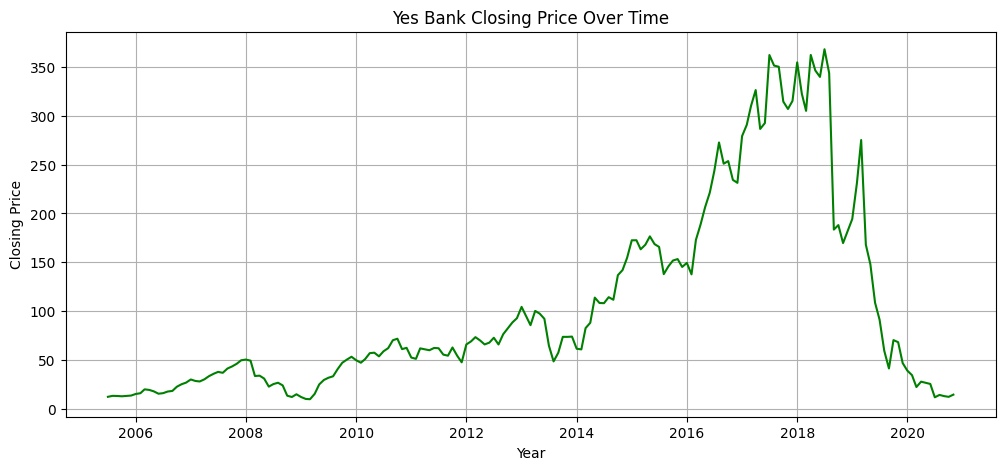

In [12]:
# Chart 1: Line Chart
plt.figure(figsize=(12, 5))

plt.plot(df['Date'], df['Close'], color='green')

plt.title('Yes Bank Closing Price Over Time')
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Track closing prices over time.

##### 2. What is/are the insight(s) found from the chart?

Prices rose into 2017–2018 and subsequently declined sharply.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Identifies historical growth and decline periods.

#### Chart - 2 - Histogram

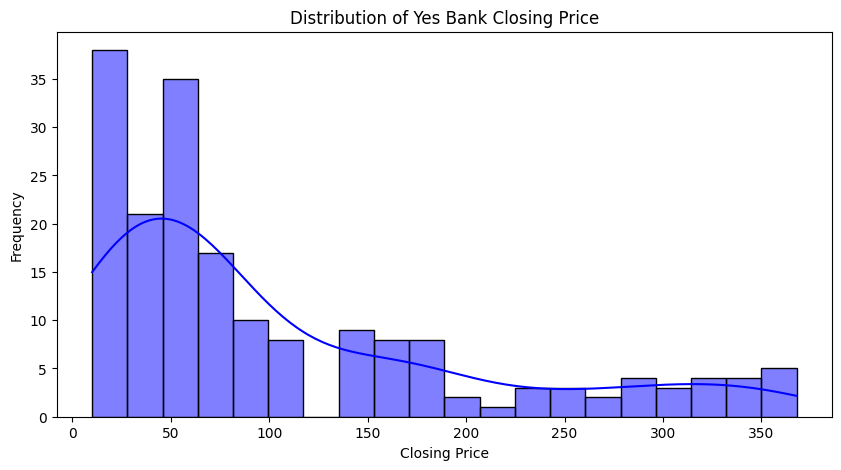

In [14]:
# Chart 2: Histogram
plt.figure(figsize=(10, 5))

sns.histplot(df['Close'], bins=20, kde=True, color='blue')

plt.title('Distribution of Yes Bank Closing Price')
plt.xlabel('Closing Price')
plt.ylabel('Frequency')
plt.show()

##### 1. Why did you pick the specific chart?

Examine frequency distribution.

##### 2. What is/are the insight(s) found from the chart?

Mean 105.20 exceeds median 62.54; the distribution is right-skewed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights the need to evaluate errors across price levels.

#### Chart - 3 - Box Plot

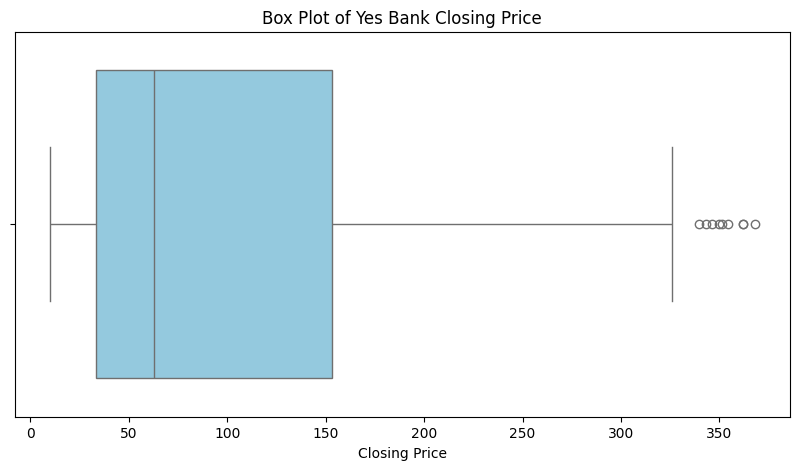

In [15]:
# Chart 3: Box Plot
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['Close'], color='skyblue')

plt.title('Box Plot of Yes Bank Closing Price')
plt.xlabel('Closing Price')
plt.show()

##### 1. Why did you pick the specific chart?

Examine quartiles and extreme observations.

##### 2. What is/are the insight(s) found from the chart?

Median is 62.54; upper-end observations extend to 367.90.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Investigate unusual values without automatically deleting genuine price movements.

#### Chart - 4 - Scatter Plot

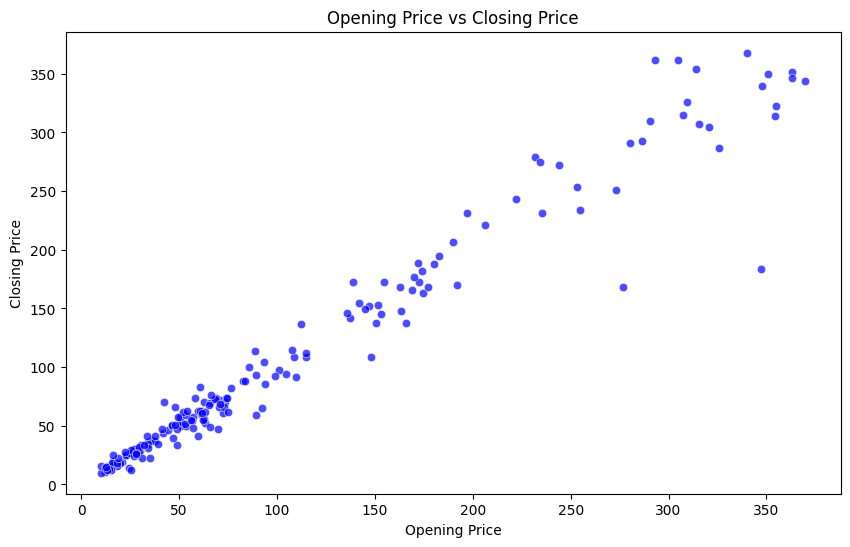

In [16]:
# Chart 4: Scatter Plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='Open',
    y='Close',
    data=df,
    color='blue',
    alpha=0.7
)

plt.title('Opening Price vs Closing Price')
plt.xlabel('Opening Price')
plt.ylabel('Closing Price')
plt.show()

##### 1. Why did you pick the specific chart?

Compare Open and Close.

##### 2. What is/are the insight(s) found from the chart?

Their correlation is approximately 0.978, indicating a strong positive linear relationship.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports testing regression models.

#### Chart - 5 - Regression Plot

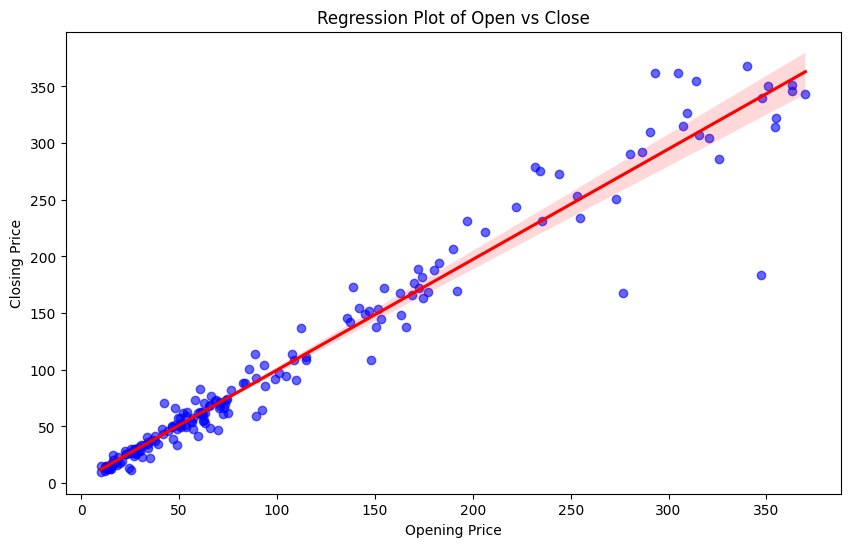

In [17]:
# Chart 5: Regression Plot
plt.figure(figsize=(10, 6))

sns.regplot(
    x='Open',
    y='Close',
    data=df,
    scatter_kws={'color': 'blue', 'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Regression Plot of Open vs Close')
plt.xlabel('Opening Price')
plt.ylabel('Closing Price')
plt.show()

##### 1. Why did you pick the specific chart?

Visualize the fitted linear relationship.

##### 2. What is/are the insight(s) found from the chart?

Open and Close have a strong positive relationship, but observations do not all lie on the fitted line.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Motivates regression evaluation on unseen data.

#### Chart - 6 - Violin Plot

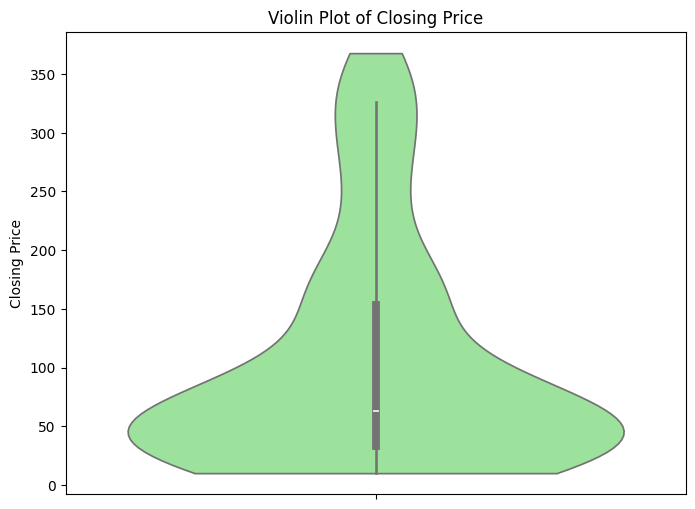

In [19]:
# Chart 6: Violin Plot
plt.figure(figsize=(8, 6))

sns.violinplot(
    y=df['Close'],
    color='lightgreen',
    inner='box',
    cut=0
)

plt.title('Violin Plot of Closing Price')
plt.ylabel('Closing Price')
plt.show()

##### 1. Why did you pick the specific chart?

Show distribution density and spread.

##### 2. What is/are the insight(s) found from the chart?

Closing prices concentrate at lower values with a long upper tail.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Helps assess typical and unusual price levels.

#### Chart - 7 - Bar Chart

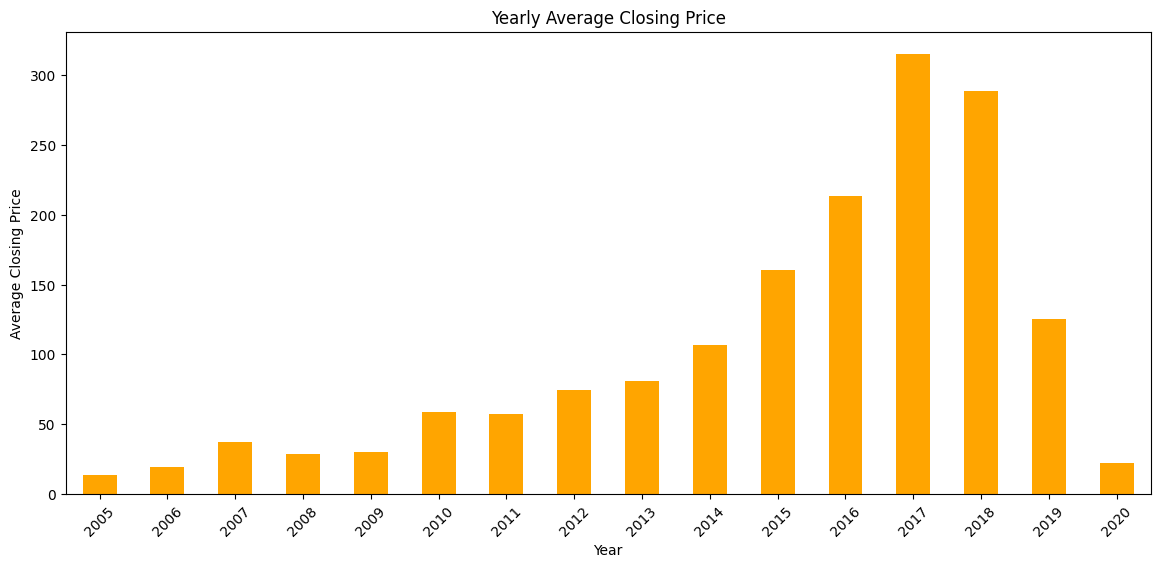

In [20]:
# Chart 7: Bar Chart
df['Year'] = df['Date'].dt.year

yearly_avg = df.groupby('Year')['Close'].mean()

plt.figure(figsize=(14, 6))

yearly_avg.plot(kind='bar', color='orange')

plt.title('Yearly Average Closing Price')
plt.xlabel('Year')
plt.ylabel('Average Closing Price')
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

Compare annual mean closing prices.

##### 2. What is/are the insight(s) found from the chart?

2017 has the highest annual mean (315.31); 2020 averages 22.11 across available months.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights historical deterioration; partial years require care.

#### Chart - 8 - Area Chart

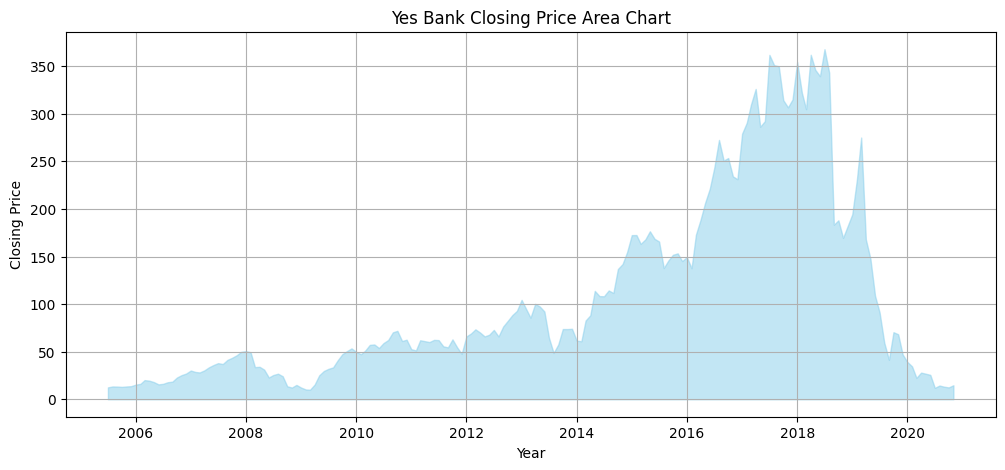

In [21]:
# Chart 8: Area Chart
plt.figure(figsize=(12, 5))

plt.fill_between(
    df['Date'],
    df['Close'],
    color='skyblue',
    alpha=0.5
)

plt.title('Yes Bank Closing Price Area Chart')
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Emphasize historical price levels.

##### 2. What is/are the insight(s) found from the chart?

The large peak in 2017–2018 is followed by a sustained decline.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Communicates historical changes clearly.

#### Chart - 9 - ECDF Plot

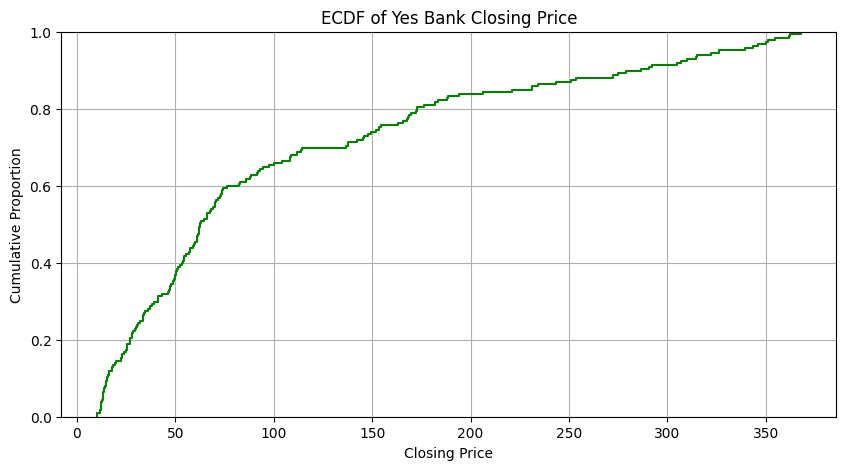

In [22]:
# Chart 9: ECDF Plot
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df,
    x='Close',
    color='green',
    stat='proportion'
)

plt.title('ECDF of Yes Bank Closing Price')
plt.xlabel('Closing Price')
plt.ylabel('Cumulative Proportion')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Measure proportion of values below a given price.

##### 2. What is/are the insight(s) found from the chart?

Approximately half of observations are at or below 62.54.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports percentile-based comparisons.

#### Chart - 10 - Rolling Average Plot

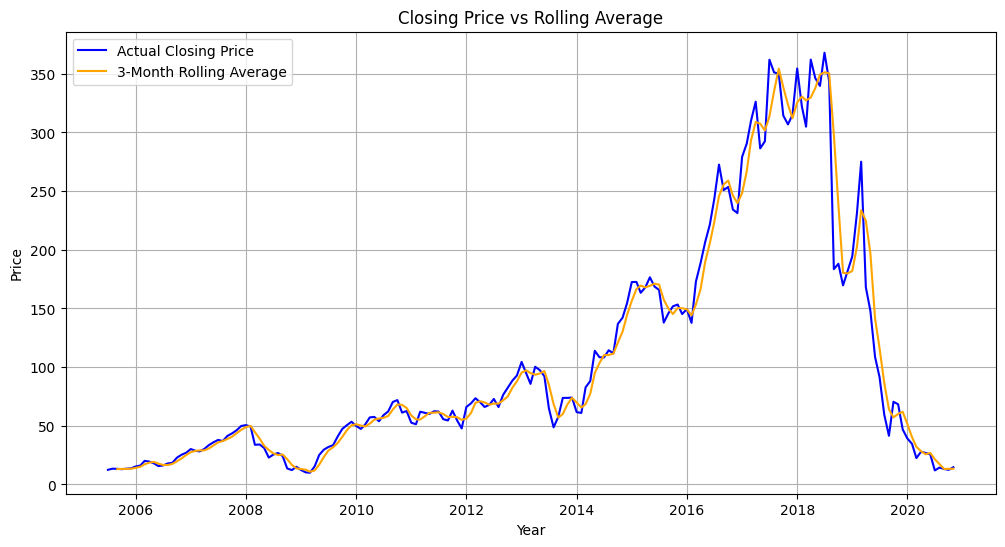

In [23]:
# Chart 10: Rolling Average Plot
df['Rolling_Avg'] = df['Close'].rolling(window=3).mean()

plt.figure(figsize=(12, 6))

plt.plot(
    df['Date'],
    df['Close'],
    label='Actual Closing Price',
    color='blue'
)

plt.plot(
    df['Date'],
    df['Rolling_Avg'],
    label='3-Month Rolling Average',
    color='orange'
)

plt.title('Closing Price vs Rolling Average')
plt.xlabel('Year')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Smooth short-term fluctuations.

##### 2. What is/are the insight(s) found from the chart?

The three-month rolling mean smooths the closing-price series and lags changes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports trend analysis; the current rolling mean contains the target and must not be used to predict it.

#### Chart - 11 - KDE Plot

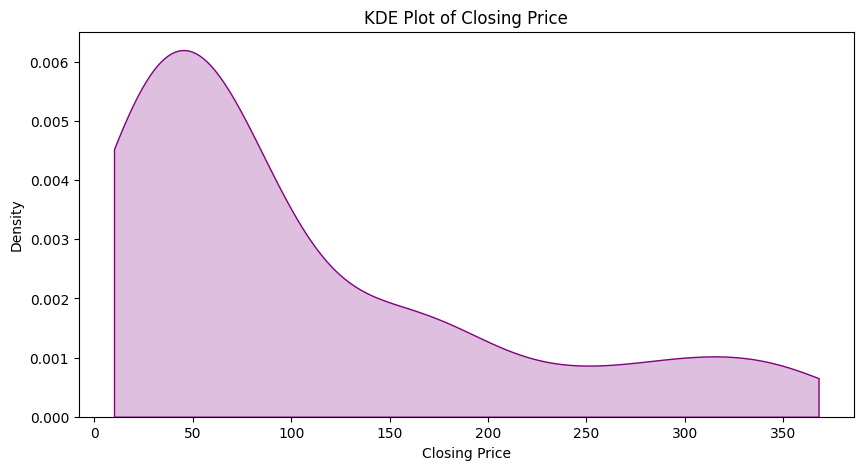

In [24]:
# Chart 11: KDE Plot
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=df,
    x='Close',
    fill=True,
    color='purple',
    bw_adjust=1,
    cut=0
)

plt.title('KDE Plot of Closing Price')
plt.xlabel('Closing Price')
plt.ylabel('Density')
plt.show()

##### 1. Why did you pick the specific chart?

Show the shape of the price distribution.

##### 2. What is/are the insight(s) found from the chart?

The distribution is concentrated toward lower prices with a right tail.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports understanding target distribution; bandwidth affects curve shape.

#### Chart - 12 - Monthly Returns Plot

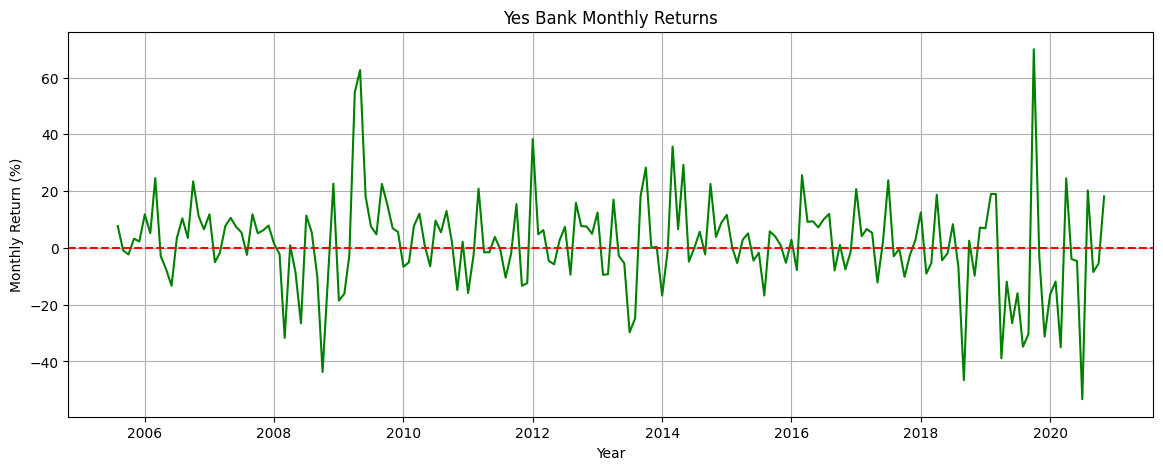

In [25]:
# Chart 12: Monthly Returns Plot
df['Monthly_Return'] = df['Close'].pct_change() * 100

plt.figure(figsize=(14, 5))

plt.plot(
    df['Date'],
    df['Monthly_Return'],
    color='green'
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Yes Bank Monthly Returns')
plt.xlabel('Year')
plt.ylabel('Monthly Return (%)')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Compare monthly percentage changes.

##### 2. What is/are the insight(s) found from the chart?

Largest increase: October 2019 (69.96%); largest decrease: July 2020 (-53.32%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Shows historical price changes and downside risk.

#### Chart - 13 - Price Range Plot

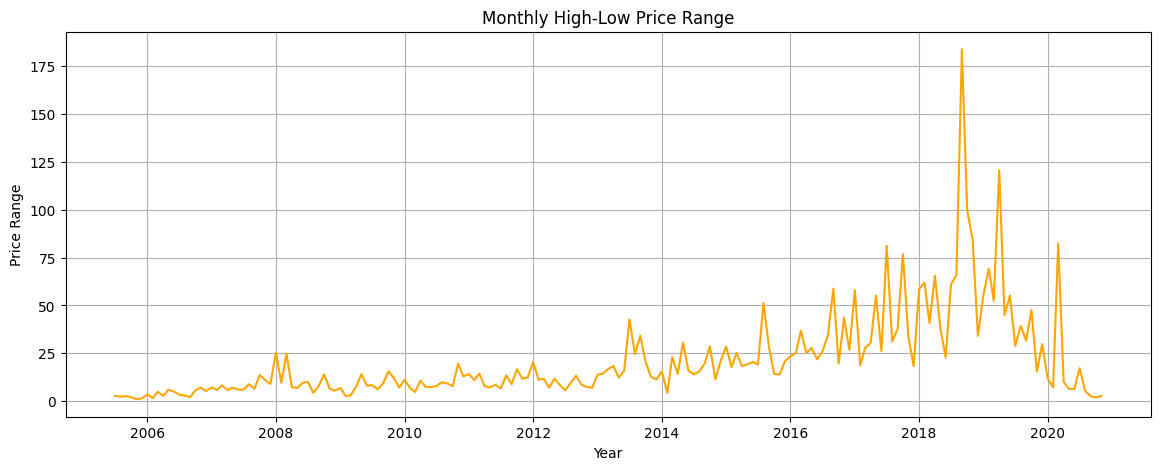

In [26]:
# Chart 13: Price Range Plot
df['Price_Range'] = df['High'] - df['Low']

plt.figure(figsize=(14, 5))

plt.plot(
    df['Date'],
    df['Price_Range'],
    color='orange'
)

plt.title('Monthly High-Low Price Range')
plt.xlabel('Year')
plt.ylabel('Price Range')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Measure monthly high-low spread.

##### 2. What is/are the insight(s) found from the chart?

September 2018 has the largest absolute range (183.85).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights large price movements; absolute ranges depend on price level.

#### Chart - 14 - Correlation Heatmap

           Open      High       Low     Close
Open   1.000000  0.993040  0.983978  0.977971
High   0.993040  1.000000  0.983422  0.985051
Low    0.983978  0.983422  1.000000  0.995358
Close  0.977971  0.985051  0.995358  1.000000


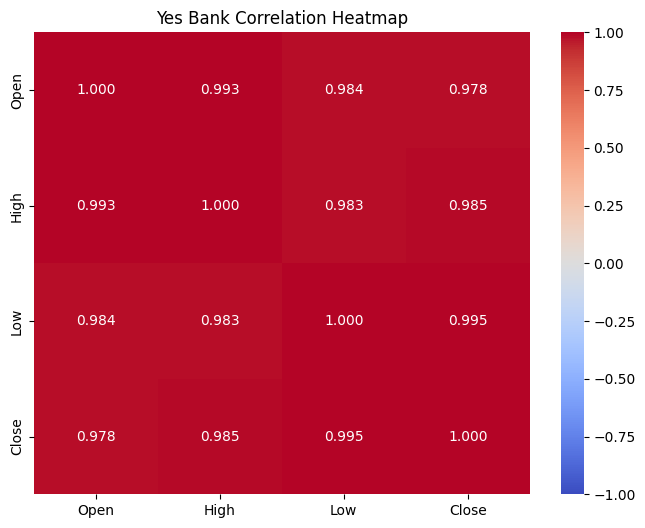

In [13]:
# Chart 14: Correlation Heatmap
correlation = df[['Open', 'High', 'Low', 'Close']].corr()
print(correlation)
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    vmin=-1,
    vmax=1
)

plt.title('Yes Bank Correlation Heatmap')
plt.show()

##### 1. Why did you pick the specific chart?

Compare linear relationships.

##### 2. What is/are the insight(s) found from the chart?

Low has the strongest correlation with Close (0.9954); High and Open also correlate strongly.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports candidate feature selection, subject to availability and leakage checks.

#### Chart - 15 - Pair Plot

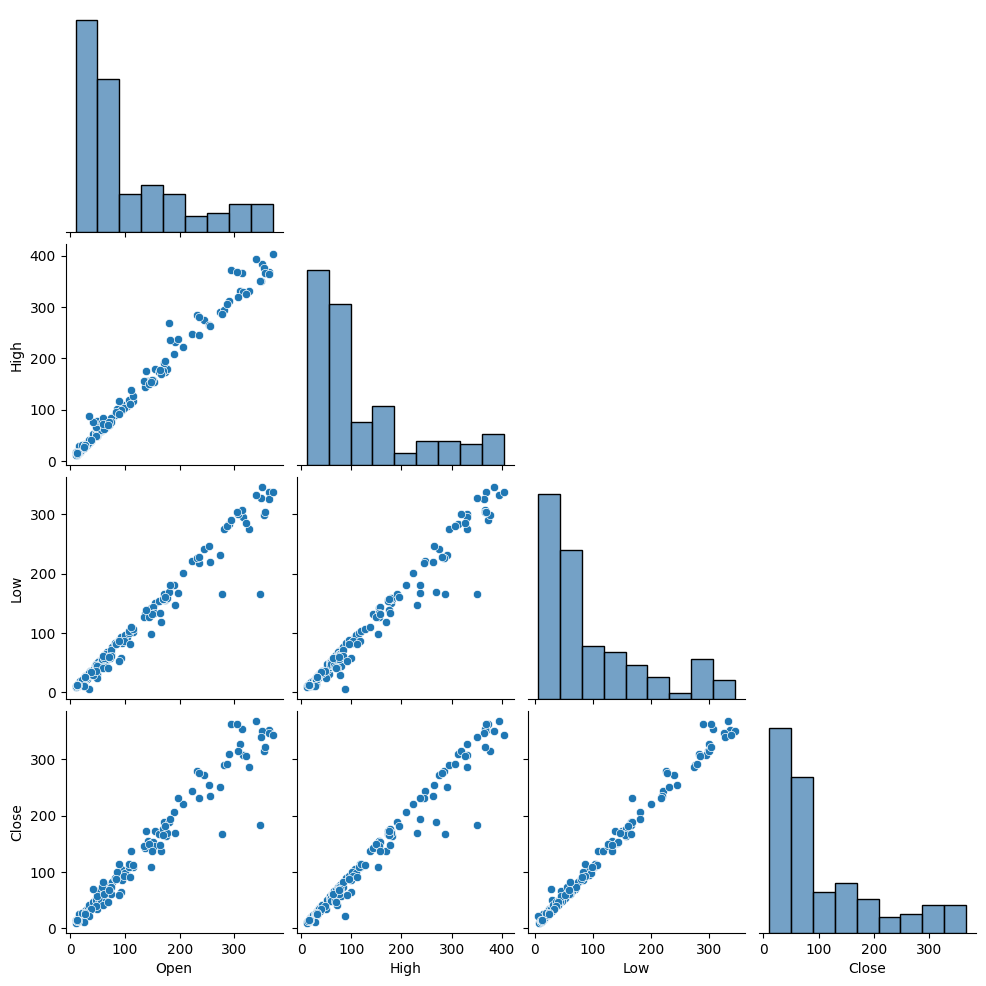

In [18]:
# Chart 15: Pair Plot
sns.pairplot(
    df[['Open', 'High', 'Low', 'Close']],
    diag_kind='hist',
    diag_kws={'color': 'steelblue'},
    corner=True
)

plt.show()

##### 1. Why did you pick the specific chart?

Compare all four numerical prices.

##### 2. What is/are the insight(s) found from the chart?

OHLC variables are strongly positively correlated.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights potential feature redundancy.

#### Chart - 16 - Multiple Line Plot

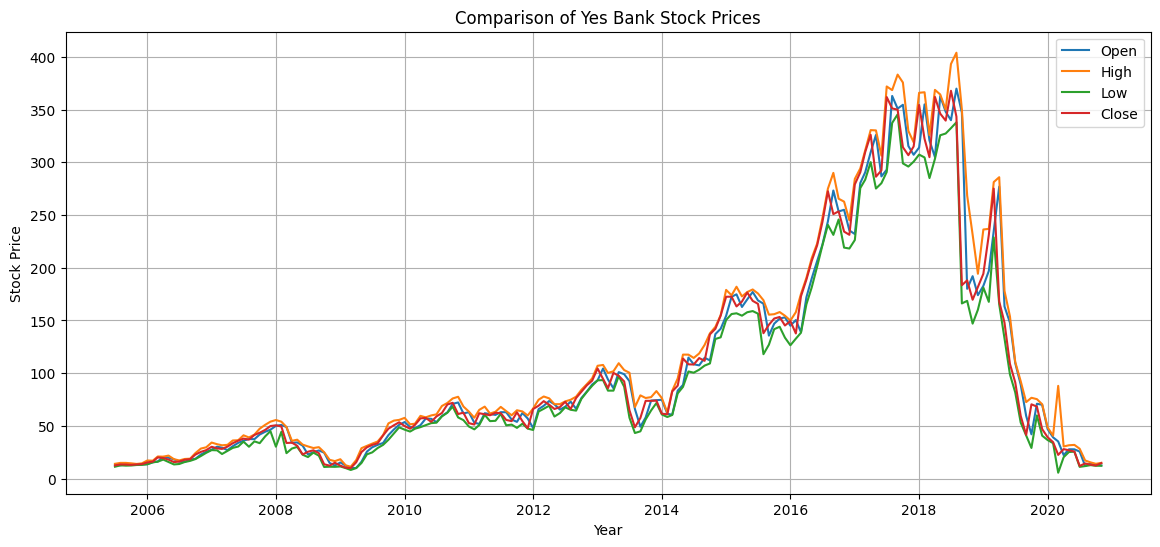

In [27]:
# Chart 16: Multiple Line Plot
plt.figure(figsize=(14, 6))

columns = ['Open', 'High', 'Low', 'Close']

for col in columns:
    plt.plot(df['Date'], df[col], label=col)

plt.title('Comparison of Yes Bank Stock Prices')
plt.xlabel('Year')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Compare OHLC trends.

##### 2. What is/are the insight(s) found from the chart?

The four prices follow broadly similar historical trends.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports checking relationships and data consistency.

#### Chart - 17 - Grouped Box Plot

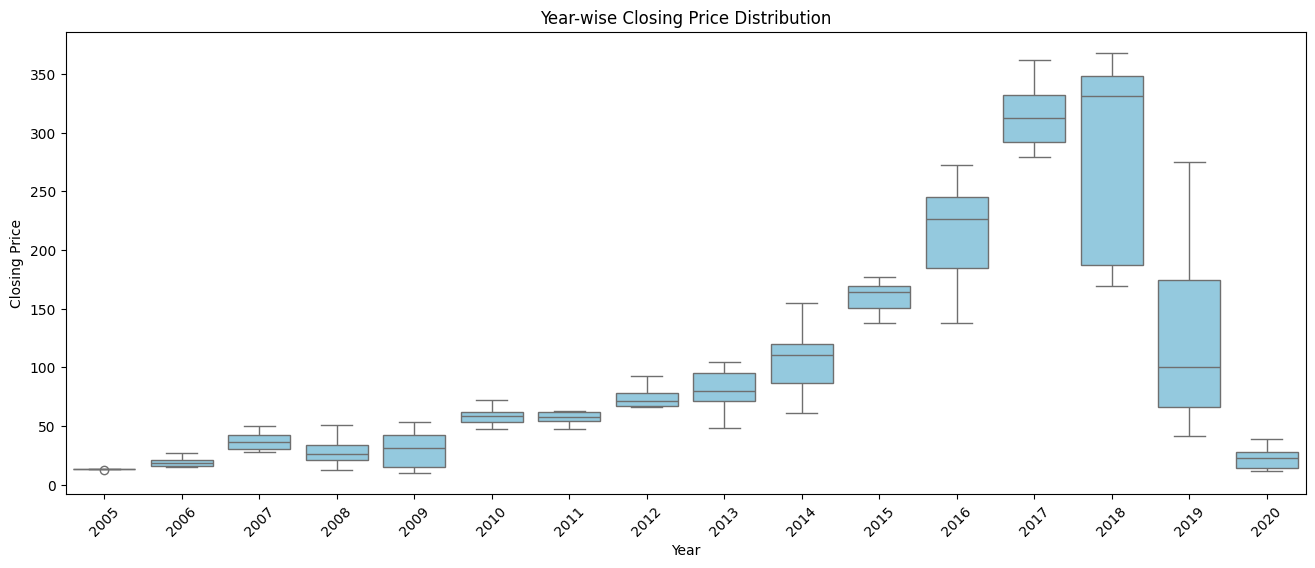

In [28]:
# Chart 17: Grouped Box Plot
plt.figure(figsize=(16, 6))

sns.boxplot(
    x='Year',
    y='Close',
    data=df,
    color='skyblue'
)

plt.title('Year-wise Closing Price Distribution')
plt.xlabel('Year')
plt.ylabel('Closing Price')
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?

Compare annual price distributions.

##### 2. What is/are the insight(s) found from the chart?

Yearly distributions shift markedly across the peak and subsequent decline.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highlights changing price regimes and within-year variation.

#### Chart - 18 - Joint Plot

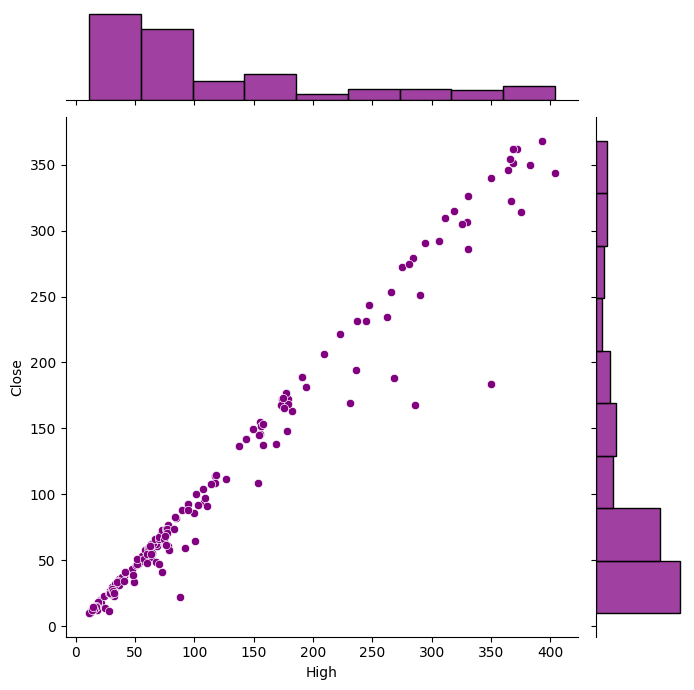

In [29]:
# Chart 18: Joint Plot
sns.jointplot(
    data=df,
    x='High',
    y='Close',
    kind='scatter',
    color='purple',
    height=7,
    marginal_kws={'color': 'purple'}
)

plt.show()

##### 1. Why did you pick the specific chart?

Combine relationship and individual price distributions.

##### 2. What is/are the insight(s) found from the chart?

High and Close correlate at approximately 0.985 and both have right-skewed distributions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports evaluating High as a feature when available.

#### Chart - 19 - Lag Plot

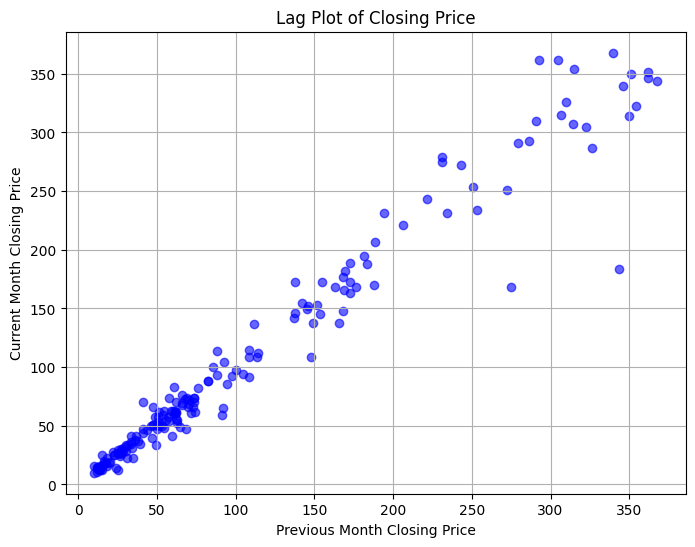

In [30]:
# Chart 19: Lag Plot
plt.figure(figsize=(8, 6))

lag_plot(
    df['Close'],
    lag=1,
    c='blue',
    alpha=0.6
)

plt.title('Lag Plot of Closing Price')
plt.xlabel('Previous Month Closing Price')
plt.ylabel('Current Month Closing Price')
plt.grid(True)
plt.show()

##### 1. Why did you pick the specific chart?

Compare consecutive closing prices.

##### 2. What is/are the insight(s) found from the chart?

Lag-one correlation is approximately 0.978.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Supports testing lagged features for forecasting; correlation does not guarantee accuracy.

#### Chart - 20 - Monthly Returns Heatmap

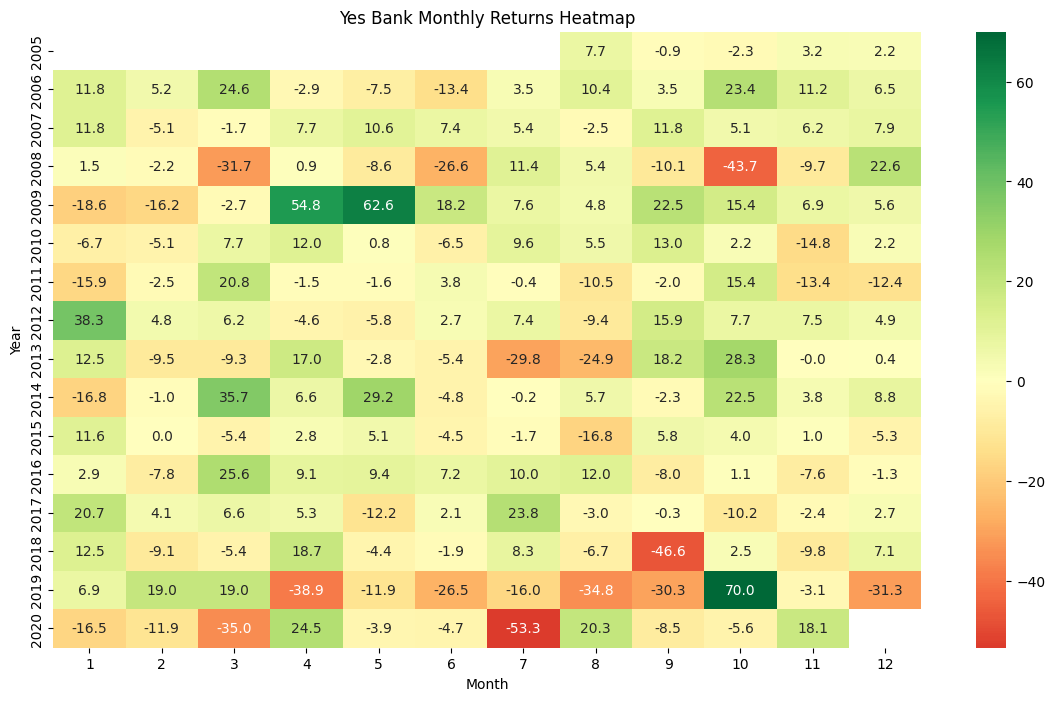

In [31]:
# Chart 20: Monthly Returns Heatmap
df['Month'] = df['Date'].dt.month

monthly_returns = df.pivot_table(
    index='Year',
    columns='Month',
    values='Monthly_Return'
)

plt.figure(figsize=(14, 8))

sns.heatmap(
    monthly_returns,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    center=0
)

plt.title('Yes Bank Monthly Returns Heatmap')
plt.xlabel('Month')
plt.ylabel('Year')
plt.show()

##### 1. Why did you pick the specific chart?

Compare returns by year and month.

##### 2. What is/are the insight(s) found from the chart?

Both positive and negative returns occur; October 2019 and July 2020 show extreme changes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Shows historical price changes without assuming repeatable seasonality.

### EDA Conclusion The dataset contains 185 monthly records with no missing or duplicate records in the original data. The average closing price is 105.20 and the median is 62.54. Prices increased and later fell sharply. Open, High and Low have strong positive correlations with Close.

Rolling averages and monthly returns create some expected missing values. Features calculated using the current closing price are not used as model inputs.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Test whether Open, High and Low each have a linear correlation with Close.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

### Hypothesis 1: Open vs Close

Null Hypothesis (H0):
There is no linear correlation between opening price and closing price.

Alternative Hypothesis (H1):
There is a linear correlation between opening price and closing price.

Significance Level: 0.05

#### 2. Perform an appropriate statistical test.

In [32]:
from scipy.stats import pearsonr

corr, p_value = pearsonr(df['Open'], df['Close'])

print("Correlation:", corr)
print("P-value:", p_value)

alpha = 0.05

if p_value <= alpha:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Correlation: 0.9779710062230934
P-value: 1.8527745058671508e-126
Reject Null Hypothesis


##### Which statistical test have you done to obtain P-Value?

Pearson correlation test.

##### Why did you choose the specific statistical test?

Both variables are numerical; Pearson measures linear association. Time dependence limits interpretation.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

### Hypothesis 2: High vs Close

H0: There is no linear correlation between High and Close.

H1: There is a linear correlation between High and Close.

Significance Level: 0.05

#### 2. Perform an appropriate statistical test.

In [33]:
corr, p_value = pearsonr(df['High'], df['Close'])

print("Correlation:", corr)
print("P-value:", p_value)

if p_value <= alpha:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Correlation: 0.9850513315779622
P-value: 9.973199888204166e-142
Reject Null Hypothesis


##### Which statistical test have you done to obtain P-Value?

Pearson correlation test.

##### Why did you choose the specific statistical test?

Both variables are numerical; Pearson measures linear association. Time dependence limits interpretation.

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

### Hypothesis 3: Low vs Close

H0: There is no linear correlation between Low and Close.

H1: There is a linear correlation between Low and Close.

Significance Level: 0.05

#### 2. Perform an appropriate statistical test.

In [34]:
corr, p_value = pearsonr(df['Low'], df['Close'])

print("Correlation:", corr)
print("P-value:", p_value)

if p_value <= alpha:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Correlation: 0.995357947647437
P-value: 5.345553676044765e-188
Reject Null Hypothesis


##### Which statistical test have you done to obtain P-Value?

Pearson correlation test.

##### Why did you choose the specific statistical test?

Both variables are numerical; Pearson measures linear association. Time dependence limits interpretation.

## Hypothesis Testing Conclusion Open, High and Low have strong positive correlations with Close. Low has the strongest correlation. All three tests reject the null hypothesis at the 5% significance level under the test assumptions. Monthly prices may depend on earlier months, so these tests are exploratory. Correlation alone does not prove future prediction accuracy.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [ ]:
print(df[["Open", "High", "Low", "Close"]].isnull().sum())

#### What all missing value imputation techniques have you used and why did you use those techniques?

No imputation needed for original prices. Lag and rolling features have expected missing values and are excluded from the model.

### 2. Handling Outliers

##### What all outlier treatment techniques have you used and why did you use those techniques?

No outlier removal: genuine price changes are retained.

### 3. Categorical Encoding

#### What all categorical encoding techniques have you used & why did you use those techniques?

Not applicable: all selected inputs are numerical.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

Not applicable: this is not a textual dataset.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

### Feature Engineering

Feature engineering is the process of creating and transforming features to improve machine learning model performance.

## Feature 1: Price Range

Price Range = High - Low

It represents the price fluctuation within a month.

In [35]:
df['Price_Range'] = df['High'] - df['Low']

df[['High', 'Low', 'Price_Range']].head()

,High,Low,Price_Range
0,14.00,11.25,2.75
1,14.88,12.55,2.33
2,14.87,12.27,2.60
3,14.47,12.40,2.07
4,13.88,12.88,1.00


### Feature Interpretation

Price Range represents the difference between the highest and lowest stock prices within a month.

A higher price range indicates greater price movement.

## Feature 2: Average Price

Average Price = (Open + High + Low) / 3

It represents the average of the opening, highest and lowest prices within a month.

In [36]:
df['Average_Price'] = (df['Open'] + df['High'] + df['Low']) / 3

df[['Open', 'High', 'Low', 'Average_Price']].head()

,Open,High,Low,Average_Price
0,13.00,14.00,11.25,12.750000
1,12.58,14.88,12.55,13.336667
2,13.48,14.87,12.27,13.540000
3,13.20,14.47,12.40,13.356667
4,13.35,13.88,12.88,13.370000


## Feature 3: Year and Month Extraction

Extract numerical year and month values from the Date column to represent historical and seasonal patterns.

In [37]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

df[['Date', 'Year', 'Month']].head()

,Date,Year,Month
0,2005-07-01,2005,7
1,2005-08-01,2005,8
2,2005-09-01,2005,9
3,2005-10-01,2005,10
4,2005-11-01,2005,11


## Feature 4: Previous Closing Price

A lag feature represents historical values from previous time periods.

The previous month's closing price is used as a potential input for predicting the current month's closing price.

In [38]:
df = df.sort_values('Date').reset_index(drop=True)

df['Previous_Close'] = df['Close'].shift(1)

df[['Date', 'Close', 'Previous_Close']].head()

,Date,Close,Previous_Close
0,2005-07-01,12.46,NaN
1,2005-08-01,13.42,12.46
2,2005-09-01,13.30,13.42
3,2005-10-01,12.99,13.30
4,2005-11-01,13.41,12.99


#### 2. Feature Selection

### Feature Selection and Data Leakage Prevention Open, High and Low are the input features. Close is the target. The extra features were explored but are not used in these five models. Features calculated from the current Close are excluded to avoid giving the model the answer.

High and Low must already be known for this same-month estimation. They are not available in advance for future forecasting.

In [39]:
selected_features = ['Open', 'High', 'Low']

target = 'Close'

print("Selected Features:", selected_features)
print("Target Variable:", target)

Selected Features: ['Open', 'High', 'Low']
Target Variable: Close


### Defining Input and Target Variables

X represents the independent variables:
Open, High and Low.

y represents the dependent variable:
Close.

The model learns the relationship between the input features and the closing price.

In [40]:
X = df[selected_features]
y = df[target]

print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

display(X.head())
display(y.head())

Input Shape: (185, 3)
Target Shape: (185,)


,Open,High,Low
0,13.00,14.00,11.25
1,12.58,14.88,12.55
2,13.48,14.87,12.27
3,13.20,14.47,12.40
4,13.35,13.88,12.88


,Close
0,12.46
1,13.42
2,13.30
3,12.99
4,13.41


##### What all feature selection methods have you used  and why?

Exploratory correlation and feature availability guided manual selection.

##### Which all features you found important and why?

Open, High and Low are strongly correlated with Close. This does not establish causation.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

Date converted to datetime; no target transformation used.

### 6. Data Scaling

##### Which method have you used to scale you data and why?

StandardScaler is fitted inside the Ridge and Lasso training pipelines. Other models use original prices.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Not needed for three inputs.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

No dimensionality reduction performed.

### 8. Data Splitting

### Train-Test Split

The dataset is divided into 80% training data and 20% testing data.

Chronological splitting is used to preserve the time order of the stock price dataset.

Shuffling is disabled to prevent future observations from entering the training set.

In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (148, 3)
X_test: (37, 3)
y_train: (148,)
y_test: (37,)


##### What data splitting ratio have you used and why?

80:20 chronological split, 148 training and 37 test rows.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Class imbalance does not apply to this continuous regression target.

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No class balancing performed.

## ***7. ML Model Implementation***

### Model 1: Multiple Linear Regression

Linear Regression is a supervised machine learning algorithm used to predict continuous numerical values.

Multiple Linear Regression is selected because the dataset contains three input features:
Open, High and Low.

The model learns a linear relationship between these features and the target variable Close.

The model estimates the same month's closing price using its Open, High and Low prices.

### Model Training

The Multiple Linear Regression model is trained using 80% of the dataset.

The model learns the relationship between Open, High and Low prices and the closing price using the Ordinary Least Squares method.

The trained model can then estimate closing prices for unseen input records.

In [42]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


### Coefficients and Intercept

The coefficients represent the relationship between each input feature and the predicted closing price.

The intercept represents the predicted value when all input features are zero.

These parameters are automatically calculated during model training using Ordinary Least Squares.

In [43]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

display(coefficients)

print("Intercept:", model.intercept_)

,Feature,Coefficient
0,Open,-0.639442
1,High,0.831176
2,Low,0.811202


Intercept: 0.2907605404005835


### Interpretation of Coefficients The learned coefficients are Open: -0.639442, High: 0.831176 and Low: 0.811202. The intercept is 0.290761. The model uses these numbers to calculate the estimated Close. The negative Open coefficient may occur because the input prices are strongly related to each other. It does not prove that increasing Open causes Close to fall.

### Model Prediction

The trained Linear Regression model is used to estimate closing prices on the testing dataset.

The predict() method applies the learned coefficients and intercept to the unseen input features.

The predicted values are stored in y_pred for further performance evaluation.

In [44]:
y_pred = model.predict(X_test)

print("Prediction Shape:", y_pred.shape)

print("First 5 Predicted Values:")
print(y_pred[:5])

Prediction Shape: (37,)
First 5 Predicted Values:
[312.78476876 312.88752248 353.03966902 325.04789031 297.29285742]


### Actual vs Predicted Values

The actual closing prices are compared with the predicted closing prices to understand the performance of the Linear Regression model.

The prediction error is calculated by subtracting the predicted value from the actual value.

Absolute error represents the magnitude of the difference between these values.

In [45]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison['Error'] = (
    comparison['Actual'] - comparison['Predicted']
)

comparison['Absolute_Error'] = comparison['Error'].abs()

display(comparison.head(10))

,Actual,Predicted,Error,Absolute_Error
0,306.80,312.784769,-5.984769,5.984769
1,315.05,312.887522,2.162478,2.162478
2,354.45,353.039669,1.410331,1.410331
3,322.25,325.047890,-2.797890,2.797890
4,304.90,297.292857,7.607143,7.607143
5,362.05,357.795012,4.254988,4.254988
6,346.20,335.358613,10.841387,10.841387
7,339.60,334.306986,5.293014,5.293014
8,367.90,379.508038,-11.608038,11.608038
9,343.40,373.710955,-30.310955,30.310955


### Actual vs Predicted Closing Prices

A line plot is used to compare actual and predicted closing prices over time.

This visualization helps identify how closely the model follows the actual stock price trend.

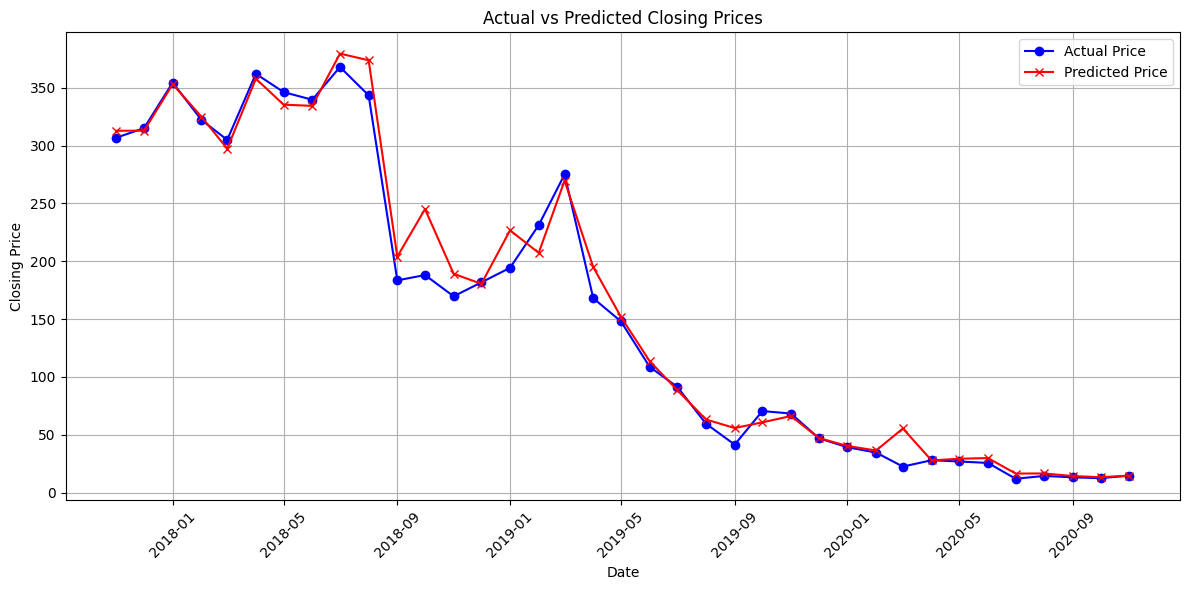

In [46]:
plt.figure(figsize=(12, 6))

plt.plot(df.loc[X_test.index, 'Date'],
         y_test.values,
         label='Actual Price',
         color='blue',
         marker='o')

plt.plot(df.loc[X_test.index, 'Date'],
         y_pred,
         label='Predicted Price',
         color='red',
         marker='x')

plt.title('Actual vs Predicted Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Graph Interpretation

The predicted closing prices closely follow the actual closing price trend.

The model captures the major downward trend observed between 2018 and 2020.

However, noticeable deviations occur during periods of significant price fluctuations.

Overall, the model demonstrates good agreement with actual closing prices.

### Actual vs Predicted Scatter Plot

A scatter plot is used to visualize the agreement between actual and predicted prices.

The diagonal reference line represents perfect predictions.

Points closer to this line indicate smaller prediction errors.

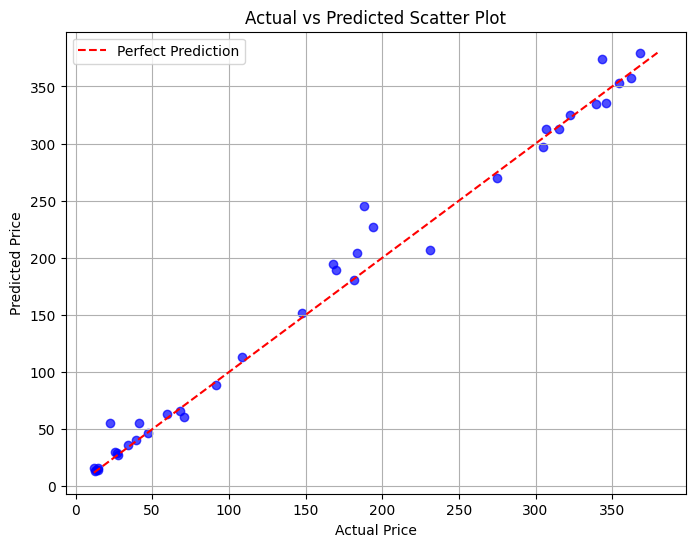

In [47]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred,
            color='blue', alpha=0.7)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot([minimum, maximum],
         [minimum, maximum],
         color='red',
         linestyle='--',
         label='Perfect Prediction')

plt.title('Actual vs Predicted Scatter Plot')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.grid(True)
plt.show()

### Graph Interpretation

Most predicted closing prices are located close to the perfect prediction line.

This indicates strong agreement between actual and predicted closing prices.

However, some observations deviate from the diagonal line, indicating overestimation and underestimation.

The model captures the overall relationship between the input features and closing price.

### Residual Plot

The residual plot displays the difference between actual and predicted closing prices.

It helps identify systematic prediction errors, unusual observations and patterns that the Linear Regression model may not capture.

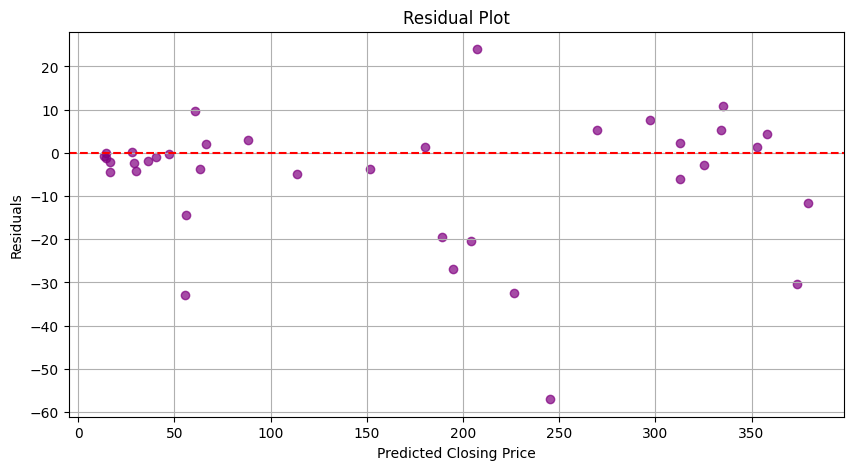

In [48]:
residuals = y_test.values - y_pred

plt.figure(figsize=(10, 5))

plt.scatter(y_pred, residuals,
            color='purple', alpha=0.7)

plt.axhline(y=0,
            color='red',
            linestyle='--')

plt.title('Residual Plot')
plt.xlabel('Predicted Closing Price')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

### Graph Interpretation

Several residuals are distributed close to the zero reference line.

However, some observations show significant prediction errors, particularly at higher predicted closing prices.

The varying spread of residuals suggests possible heteroscedasticity.

These observations indicate that the Linear Regression model has limitations and that alternative regression models should be evaluated.

### Linear Regression Conclusion

The Multiple Linear Regression model successfully estimates Yes Bank closing prices using Open, High and Low prices.

The visualizations demonstrate good overall agreement between actual and predicted values.

However, significant prediction errors are observed for some testing records.

Additional regression models will be evaluated to identify the most suitable model.

The current model estimates same-month closing prices rather than forecasting future prices.

### Model 2: Ridge Regression

Ridge Regression is an extension of Linear Regression that uses L2 regularization.

It adds a penalty based on the squared coefficients to the loss function.

This helps control model complexity and reduce the effects of multicollinearity.

Ridge Regression is implemented to evaluate whether regularization improves the estimation of Yes Bank closing prices.

In [49]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

print("Ridge Model Trained Successfully")
print("First 5 Predictions:")
print(ridge_pred[:5])

Ridge Model Trained Successfully
First 5 Predictions:
[315.31681339 312.94725219 340.44595545 336.35638516 306.76235188]


### Model 3: Lasso Regression

Lasso Regression is a regularized regression algorithm that uses L1 regularization.

It adds a penalty based on the absolute values of the model coefficients.

Lasso can reduce some feature coefficients to zero, enabling automatic feature selection.

This model is implemented to evaluate whether L1 regularization improves the estimation of Yes Bank closing prices.

In [50]:
from sklearn.linear_model import Lasso

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0, max_iter=10000)
)

lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

print("Lasso Model Trained Successfully")
print("First 5 Predictions:")
print(lasso_pred[:5])

Lasso Model Trained Successfully
First 5 Predictions:
[313.67419147 310.73225553 337.21934557 336.09324504 306.1721798 ]


### Model 4: Decision Tree Regression

Decision Tree Regression is a supervised machine learning algorithm that uses decision rules to predict numerical values.

The algorithm recursively splits the dataset into smaller groups by reducing squared prediction errors.

The final prediction is obtained from the average target value of the corresponding leaf node.

Maximum tree depth is restricted to control model complexity and reduce overfitting.

In [51]:
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree Trained Successfully")

print("First 5 Predictions:")
print(dt_pred[:5])

Decision Tree Trained Successfully
First 5 Predictions:
[326.14  326.14  356.555 356.555 309.82 ]


### Model 5: Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm that combines multiple Decision Trees.

Each tree is trained using a bootstrap sample of the training dataset.

The final prediction is calculated by averaging the predictions of all trees.

This approach helps reduce overfitting and improve model generalization.

Random Forest is implemented to estimate Yes Bank closing prices.

In [52]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Trained Successfully")

print("First 5 Predictions:")
print(rf_pred[:5])

Random Forest Trained Successfully
First 5 Predictions:
[320.29825143 319.70932643 340.07371976 339.56572976 309.83159167]


### Model Evaluation and Comparison

Cross-validation and hyperparameter tuning were not performed for these baseline models. Time-series cross-validation is future work.

## Mean Absolute Error (MAE)

Mean Absolute Error measures the average absolute difference between actual and predicted closing prices.

A lower MAE indicates better prediction performance.

MAE is calculated for all five regression models to compare their prediction errors.

In [53]:
from sklearn.metrics import mean_absolute_error

mae_lr = mean_absolute_error(y_test, y_pred)

mae_ridge = mean_absolute_error(y_test, ridge_pred)

mae_lasso = mean_absolute_error(y_test, lasso_pred)

mae_dt = mean_absolute_error(y_test, dt_pred)

mae_rf = mean_absolute_error(y_test, rf_pred)

print("Linear Regression MAE:", mae_lr)
print("Ridge Regression MAE:", mae_ridge)
print("Lasso Regression MAE:", mae_lasso)
print("Decision Tree MAE:", mae_dt)
print("Random Forest MAE:", mae_rf)

Linear Regression MAE: 9.784256877932837
Ridge Regression MAE: 12.635690272001847
Lasso Regression MAE: 13.447760284415102
Decision Tree MAE: 14.745340733590727
Random Forest MAE: 13.852424197329267


### MAE Interpretation

Linear Regression achieved the lowest MAE of 9.7843 among the five regression models.

This indicates that its predicted closing prices differ from the actual closing prices by approximately Rs. 9.78 on average.

Decision Tree Regression recorded the highest MAE of 14.7453.

Based on MAE, Linear Regression performs best on the current testing dataset.
Further evaluation using MSE, RMSE and R² Score is required.

## Mean Squared Error (MSE)

Mean Squared Error measures the average squared difference between actual and predicted closing prices.

MSE penalizes larger prediction errors more heavily than smaller errors.

A lower MSE indicates better prediction performance.

MSE is calculated for all five regression models to evaluate their performance.

In [54]:
from sklearn.metrics import mean_squared_error

mse_lr = mean_squared_error(y_test, y_pred)

mse_ridge = mean_squared_error(y_test, ridge_pred)

mse_lasso = mean_squared_error(y_test, lasso_pred)

mse_dt = mean_squared_error(y_test, dt_pred)

mse_rf = mean_squared_error(y_test, rf_pred)

print("Linear Regression MSE:", mse_lr)
print("Ridge Regression MSE:", mse_ridge)
print("Lasso Regression MSE:", mse_lasso)
print("Decision Tree MSE:", mse_dt)
print("Random Forest MSE:", mse_rf)

Linear Regression MSE: 250.33067629079187
Ridge Regression MSE: 375.7794042909253
Lasso Regression MSE: 423.5334885081003
Decision Tree MSE: 435.81475872762917
Random Forest MSE: 439.4115974230244


### MSE Interpretation

Linear Regression achieved the lowest MSE of 250.3307 among all five regression models.

Random Forest Regression recorded the highest MSE of 439.4116.

Since MSE penalizes larger prediction errors, Linear Regression demonstrates better performance according to squared error on the current testing dataset.

Linear Regression achieved the lowest values in both MAE and MSE.

## Root Mean Squared Error (RMSE)

Root Mean Squared Error is the square root of Mean Squared Error.

RMSE measures prediction errors in the original unit of the target variable.

It penalizes larger prediction errors more heavily than MAE.

A lower RMSE indicates better prediction performance.

In [55]:
import numpy as np

rmse_lr = np.sqrt(mse_lr)

rmse_ridge = np.sqrt(mse_ridge)

rmse_lasso = np.sqrt(mse_lasso)

rmse_dt = np.sqrt(mse_dt)

rmse_rf = np.sqrt(mse_rf)

print("Linear Regression RMSE:", rmse_lr)
print("Ridge Regression RMSE:", rmse_ridge)
print("Lasso Regression RMSE:", rmse_lasso)
print("Decision Tree RMSE:", rmse_dt)
print("Random Forest RMSE:", rmse_rf)

Linear Regression RMSE: 15.821841747748328
Ridge Regression RMSE: 19.385030417590922
Lasso Regression RMSE: 20.57992926392363
Decision Tree RMSE: 20.876176822580067
Random Forest RMSE: 20.962146775152213


### RMSE Interpretation

Linear Regression achieved the lowest RMSE of 15.8218 among all five regression models.

Random Forest Regression recorded the highest RMSE of 20.9621.

The results indicate that Linear Regression has lower prediction error magnitude than the other models on the testing dataset.

Linear Regression achieved the lowest MAE, MSE and RMSE values.

## R² Score (Coefficient of Determination)

R² Score measures how well a regression model explains the variation in the target variable compared with a mean-value baseline.

An R² score of 1 indicates perfect predictions.

A score of 0 indicates performance equivalent to the mean-value baseline.

A negative R² indicates performance worse than the mean-value baseline.

A higher R² score indicates better regression performance on the same testing dataset.

In [56]:
from sklearn.metrics import r2_score

r2_lr = r2_score(y_test, y_pred)

r2_ridge = r2_score(y_test, ridge_pred)

r2_lasso = r2_score(y_test, lasso_pred)

r2_dt = r2_score(y_test, dt_pred)

r2_rf = r2_score(y_test, rf_pred)

print("Linear Regression R2:", r2_lr)
print("Ridge Regression R2:", r2_ridge)
print("Lasso Regression R2:", r2_lasso)
print("Decision Tree R2:", r2_dt)
print("Random Forest R2:", r2_rf)

Linear Regression R2: 0.9847535767466384
Ridge Regression R2: 0.9771131052230282
Lasso Regression R2: 0.9742046363496171
Decision Tree R2: 0.9734566439476059
Random Forest R2: 0.9732375780067606


### R² Score Interpretation

Linear Regression achieved the highest R²
score of 0.984754 among all five models.

This indicates that Linear Regression explains approximately 98.48% of the variation in closing prices on the testing dataset.

All five regression models achieved R² scores above 0.97.

Linear Regression demonstrated the best performance across all four evaluation metrics on the current testing dataset.

## Model Performance Comparison

The performance of all five regression models is compared using MAE, MSE, RMSE and R² Score.

Lower MAE, MSE and RMSE values indicate better prediction performance, while a higher R² score indicates a better fit relative to the mean-value baseline.

A comparison table is created to identify the best-performing regression model.

In [57]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Ridge Regression',
        'Lasso Regression',
        'Decision Tree',
        'Random Forest'
    ],

    'MAE': [
        mae_lr, mae_ridge, mae_lasso,
        mae_dt, mae_rf
    ],

    'MSE': [
        mse_lr, mse_ridge, mse_lasso,
        mse_dt, mse_rf
    ],

    'RMSE': [
        rmse_lr, rmse_ridge, rmse_lasso,
        rmse_dt, rmse_rf
    ],

    'R2 Score': [
        r2_lr, r2_ridge, r2_lasso,
        r2_dt, r2_rf
    ]
})

results = results.sort_values(
    by='R2 Score',
    ascending=False
).reset_index(drop=True)

display(results.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,9.7843,250.3307,15.8218,0.9848
1,Ridge Regression,12.6357,375.7794,19.3850,0.9771
2,Lasso Regression,13.4478,423.5335,20.5799,0.9742
3,Decision Tree,14.7453,435.8148,20.8762,0.9735
4,Random Forest,13.8524,439.4116,20.9621,0.9732


## Model Performance Visualization

Bar charts are used to compare the performance of all five regression models.

MAE, MSE, RMSE and R² Score are visualized to identify differences in model performance.

The best-performing model is identified based on the evaluation results.

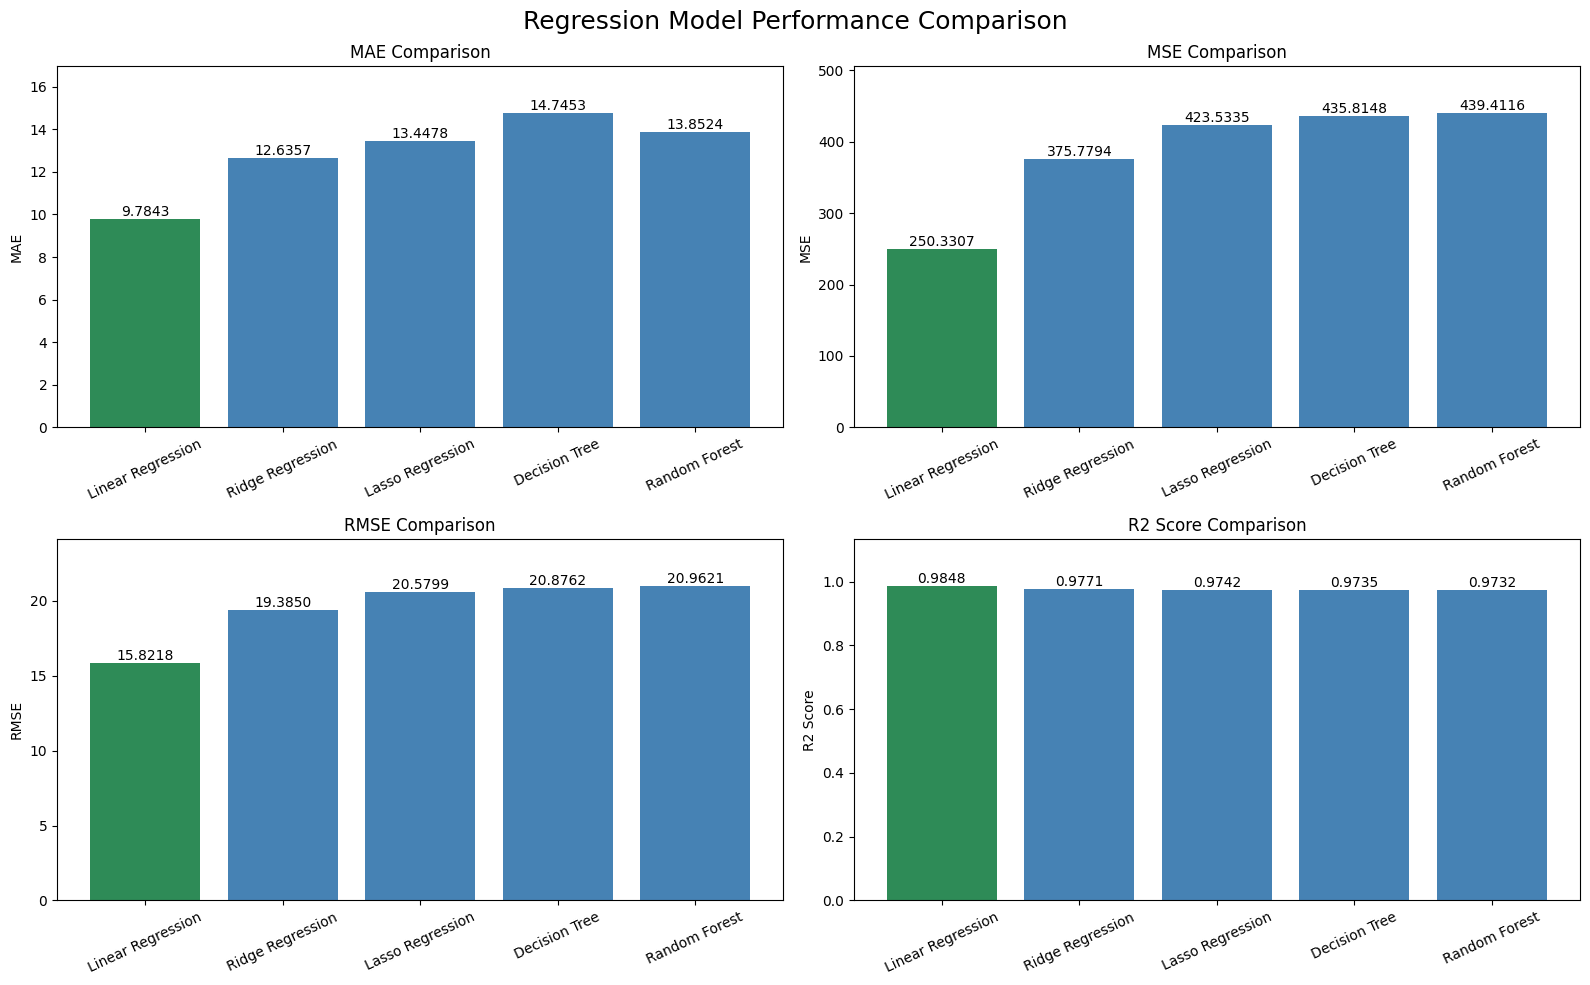

In [58]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

metrics = ['MAE', 'MSE', 'RMSE', 'R2 Score']

for ax, metric in zip(axes.flatten(), metrics):

    colors = [
        'seagreen' if name == 'Linear Regression'
        else 'steelblue'
        for name in results['Model']
    ]

    ax.bar(results['Model'], results[metric],
           color=colors)

    ax.set_title(metric + ' Comparison')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=25)

    for i, value in enumerate(results[metric]):
        ax.text(i, value, f'{value:.4f}',
                ha='center', va='bottom')

    ax.margins(y=0.15)

plt.suptitle('Regression Model Performance Comparison',
             fontsize=18)

plt.tight_layout()
plt.show()

### Model Comparison Visualization Insights

- Linear Regression achieved the lowest
  MAE, MSE and RMSE values.

- Linear Regression achieved the highest
  R² Score among all five models.

- Ridge Regression was the second-best
  performing model across all four metrics.

- All five models achieved R² scores
  above 0.97.

- Linear Regression is the best-performing
  model on the current testing dataset.

## Best Model Identification

The best-performing model is identified using the highest R² Score.

The corresponding MAE, MSE and RMSE values are also displayed to summarize its prediction performance.

In [59]:
best_index = results['R2 Score'].idxmax()

best_model = results.loc[best_index]

print("Best Performing Model:", best_model['Model'])

print("MAE:", best_model['MAE'])
print("MSE:", best_model['MSE'])
print("RMSE:", best_model['RMSE'])
print("R2 Score:", best_model['R2 Score'])

Best Performing Model: Linear Regression
MAE: 9.784256877932837
MSE: 250.33067629079187
RMSE: 15.821841747748328
R2 Score: 0.9847535767466384


### Model Evaluation Conclusion

Five regression models were implemented and evaluated using MAE, MSE, RMSE and R² Score.

Linear Regression achieved the best performance across all four metrics.

The model achieved:

- MAE: 9.7843
- MSE: 250.3307
- RMSE: 15.8218
- R² Score: 0.984754

Linear Regression explains approximately
98.48% of the variation in closing prices on the current testing dataset.

Therefore, Linear Regression is selected as the best-performing model among the five evaluated models.

### Limitations

The model estimates same-month closing prices using Open, High and Low values.

The results do not establish future stock price forecasting accuracy.

Additional time-series validation is required to confirm model generalization and model selection.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

MAE gives average absolute error, MSE and RMSE emphasize larger errors, and R² measures explained variation.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

Linear Regression had the best scores on the current test set. Independent validation is still needed.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

The coefficient table above explains the linear model directly. Correlated inputs make individual coefficients difficult to interpret as importance. No external explainability tool was used.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [60]:
import joblib

joblib.dump(model, 'yes_bank_model.pkl')

print("Model saved successfully")

Model saved successfully


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [61]:
loaded_model = joblib.load('yes_bank_model.pkl')

loaded_pred = loaded_model.predict(X_test)

print("Model loaded successfully")

print("First 5 Predictions:")
print(loaded_pred[:5])

print("Predictions Match:",
      np.allclose(y_pred, loaded_pred))

Model loaded successfully
First 5 Predictions:
[312.78476876 312.88752248 353.03966902 325.04789031 297.29285742]
Predictions Match: True


## User-Input Closing Price Prediction

A user-input prediction system is created using the saved Linear Regression model.

The user enters the opening, highest and lowest stock prices.

The trained model processes these inputs and estimates the corresponding closing price.

Input validation is performed to prevent invalid stock price combinations.

This system estimates same-month closing prices and does not forecast future prices.

In [ ]:
try:
    open_price = float(input('Enter Opening Price: '))
    high_price = float(input('Enter Highest Price: '))
    low_price = float(input('Enter Lowest Price: '))

    if np.isfinite([open_price, high_price, low_price]).all() and 0 < low_price <= open_price <= high_price:
        input_data = pd.DataFrame({
            'Open': [open_price],
            'High': [high_price],
            'Low': [low_price]
        })
        prediction = loaded_model.predict(input_data)
        print(f'Estimated Closing Price: Rs. {prediction[0]:.2f}')
        if not low_price <= prediction[0] <= high_price:
            print('Note: The estimate is outside the given price range.')
    else:
        print('Invalid stock price values')
except ValueError:
    print('Please enter valid numbers.')

# Final Project Conclusion I analyzed historical Yes Bank stock prices and compared five regression models. Linear Regression performed best on the current test set.

## Key Results
- MAE: 9.7843
- MSE: 250.3307
- RMSE: 15.8218
- R²: 0.984754

## Limitations The model estimates the closing price using the same month's Open, High and Low. It cannot forecast future prices using unknown inputs. Further validation is needed because the test results were used to compare models.

## Future Improvements Use newer data, try time-series forecasting with past prices, validate models using time-series cross-validation and create a simple web application.